# Logistic Regression + Linear SVM


- A probability-blend weight;
- combine their log-odds instead of probabilities;
- let a small Logistic Regression model learn how to combine them (stacking).

We'll pick weights using the development out-of-fold predictions. The later-season holdout is only used to check the finished methods, not to choose their weights.

## 1. Load the saved predictions

Run `src/compare_models.ipynb` first. It creates the prediction files used here. The OOF file has development predictions made on rows the base models did not train on; the temporal file has predictions for later seasons.

In [8]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.calibration import calibration_curve
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, brier_score_loss, log_loss, roc_auc_score

SEARCH_ROOTS = [Path.cwd().resolve(), *Path.cwd().resolve().parents]
PROJECT_ROOT = next(
    (p for p in SEARCH_ROOTS
     if (p / "data/processed/model_comparison_oof_predictions.csv").exists()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Can't find the OOF prediction file. Run src/compare_models.ipynb first."
    )

PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
REPORT_DIR = PROJECT_ROOT / "reports"
REPORT_DIR.mkdir(parents=True, exist_ok=True)

OOF_PATH = PROCESSED_DIR / "model_comparison_oof_predictions.csv"
HOLDOUT_PATH = PROCESSED_DIR / "model_comparison_temporal_predictions.csv"

print("Project folder:", PROJECT_ROOT)
print("OOF file found:", OOF_PATH.exists())
print("Temporal holdout file found:", HOLDOUT_PATH.exists())

Project folder: C:\Users\Lenovo\Documents\IPL ML
OOF file found: True
Temporal holdout file found: True


## 2. Check the files

We need the true result and both models' predicted probabilities. If the column names differ from these, stop here and check the comparison notebook's exports.

In [9]:
oof = pd.read_csv(OOF_PATH)
holdout = pd.read_csv(HOLDOUT_PATH)

LR_COL = "p_logistic_regression"
SVM_COL = "p_linear_svm"
TARGET_COL = "y_true"
GROUP_COL = "match_id"
REQUIRED_OOF = {LR_COL, SVM_COL, TARGET_COL, GROUP_COL, "fold"}
REQUIRED_HOLDOUT = {LR_COL, SVM_COL, TARGET_COL, GROUP_COL}

missing_oof = REQUIRED_OOF - set(oof.columns)
missing_holdout = REQUIRED_HOLDOUT - set(holdout.columns)
if missing_oof:
    raise ValueError(f"Missing OOF columns: {sorted(missing_oof)}")
if missing_holdout:
    raise ValueError(f"Missing holdout columns: {sorted(missing_holdout)}")

for name, frame in [("OOF", oof), ("holdout", holdout)]:
    needed = [LR_COL, SVM_COL, TARGET_COL, GROUP_COL]
    if frame[needed].isna().any().any():
        raise ValueError(f"{name} file has missing values in required columns.")
    if not frame[TARGET_COL].isin([0, 1]).all():
        raise ValueError(f"{name} target must contain only 0 and 1.")
    for col in [LR_COL, SVM_COL]:
        if not frame[col].between(0, 1).all():
            raise ValueError(f"{name} column {col} has probabilities outside [0, 1].")

print(f"Development OOF: {len(oof):,} rows, {oof[GROUP_COL].nunique():,} matches")
print(f"Temporal holdout: {len(holdout):,} rows, {holdout[GROUP_COL].nunique():,} matches")
if "season_id" in holdout.columns:
    print("Holdout seasons:", sorted(holdout["season_id"].dropna().unique().tolist()))

Development OOF: 105,663 rows, 953 matches
Temporal holdout: 11,895 rows, 110 matches
Holdout seasons: [2025, 2026]


## 3. A few helper functions

We'll compare log loss, Brier score, ROC-AUC and accuracy. Log loss and Brier score tell us more about the quality of the probabilities; accuracy only checks the 0.5 cutoff.

In [10]:
EPS = 1e-6

def clip_probabilities(probabilities):
    return np.clip(np.asarray(probabilities, dtype=float), EPS, 1 - EPS)


def score_probabilities(y_true, probabilities):
    y_true = np.asarray(y_true, dtype=int)
    probabilities = clip_probabilities(probabilities)
    return {
        "log_loss": log_loss(y_true, probabilities, labels=[0, 1]),
        "brier_score": brier_score_loss(y_true, probabilities),
        "roc_auc": roc_auc_score(y_true, probabilities),
        "accuracy": accuracy_score(y_true, probabilities >= 0.5),
    }


def probability_blend(p_lr, p_svm, weight_lr):
    """weight_lr is the LR weight; the rest goes to SVM."""
    return weight_lr * np.asarray(p_lr) + (1 - weight_lr) * np.asarray(p_svm)


def log_odds_blend(p_lr, p_svm, weight_lr):
    """Blend log-odds, then turn them back into probabilities."""
    p_lr = clip_probabilities(p_lr)
    p_svm = clip_probabilities(p_svm)
    lr_log_odds = np.log(p_lr / (1 - p_lr))
    svm_log_odds = np.log(p_svm / (1 - p_svm))
    combined = weight_lr * lr_log_odds + (1 - weight_lr) * svm_log_odds
    return 1 / (1 + np.exp(-np.clip(combined, -30, 30)))

## 4. Find a better weight

We'll test LR weights from 0% to 100% in 1% steps. The rest of each blend's weight goes to SVM. We choose the weight with the lowest log loss on development OOF predictions only. The OOF score after choosing a weight is a selection score, so it may look a little better than a fresh evaluation.

In [11]:
y_oof = oof[TARGET_COL].to_numpy(dtype=int)
weights = np.round(np.linspace(0, 1, 101), 2)
search_rows = []

for weight_lr in weights:
    p_prob = probability_blend(oof[LR_COL], oof[SVM_COL], weight_lr)
    p_log_odds = log_odds_blend(oof[LR_COL], oof[SVM_COL], weight_lr)
    search_rows.append({
        "weight_lr": weight_lr,
        "weight_svm": 1 - weight_lr,
        "probability_log_loss": score_probabilities(y_oof, p_prob)["log_loss"],
        "probability_brier_score": score_probabilities(y_oof, p_prob)["brier_score"],
        "log_odds_log_loss": score_probabilities(y_oof, p_log_odds)["log_loss"],
        "log_odds_brier_score": score_probabilities(y_oof, p_log_odds)["brier_score"],
    })

weight_search = pd.DataFrame(search_rows)
best_prob_row = weight_search.loc[weight_search["probability_log_loss"].idxmin()]
best_log_odds_row = weight_search.loc[weight_search["log_odds_log_loss"].idxmin()]
BEST_PROB_WEIGHT = float(best_prob_row["weight_lr"])
BEST_LOG_ODDS_WEIGHT = float(best_log_odds_row["weight_lr"])

print(f"Best probability-blend weights: LR={BEST_PROB_WEIGHT:.0%}, SVM={1-BEST_PROB_WEIGHT:.0%}")
print(f"Best log-odds-blend weights:    LR={BEST_LOG_ODDS_WEIGHT:.0%}, SVM={1-BEST_LOG_ODDS_WEIGHT:.0%}")
display(weight_search.sort_values("probability_log_loss").head(10).round(5))
display(weight_search.sort_values("log_odds_log_loss").head(10).round(5))

Best probability-blend weights: LR=63%, SVM=37%
Best log-odds-blend weights:    LR=61%, SVM=39%


,weight_lr,weight_svm,probability_log_loss,probability_brier_score,log_odds_log_loss,log_odds_brier_score
63,0.63,0.37,0.44047,0.14533,0.44048,0.14533
64,0.64,0.36,0.44047,0.14533,0.44048,0.14533
62,0.62,0.38,0.44047,0.14533,0.44048,0.14533
65,0.65,0.35,0.44047,0.14534,0.44048,0.14534
61,0.61,0.39,0.44047,0.14533,0.44048,0.14533
66,0.66,0.34,0.44047,0.14534,0.44048,0.14534
60,0.60,0.40,0.44047,0.14533,0.44048,0.14533
67,0.67,0.33,0.44047,0.14534,0.44048,0.14534
59,0.59,0.41,0.44047,0.14533,0.44048,0.14533
68,0.68,0.32,0.44047,0.14534,0.44048,0.14534


,weight_lr,weight_svm,probability_log_loss,probability_brier_score,log_odds_log_loss,log_odds_brier_score
61,0.61,0.39,0.44047,0.14533,0.44048,0.14533
60,0.60,0.40,0.44047,0.14533,0.44048,0.14533
62,0.62,0.38,0.44047,0.14533,0.44048,0.14533
59,0.59,0.41,0.44047,0.14533,0.44048,0.14533
63,0.63,0.37,0.44047,0.14533,0.44048,0.14533
58,0.58,0.42,0.44047,0.14533,0.44048,0.14533
64,0.64,0.36,0.44047,0.14533,0.44048,0.14533
57,0.57,0.43,0.44047,0.14533,0.44048,0.14533
65,0.65,0.35,0.44047,0.14534,0.44048,0.14534
56,0.56,0.44,0.44047,0.14533,0.44048,0.14533


## 5. Build the blends

The first method averages probabilities. The second averages log-odds, which changes how far apart confident predictions can be. We'll keep the 50/50 blend as a reference.

In [12]:
def add_blend_predictions(frame):
    frame = frame.copy()
    frame["p_blend_50_50"] = probability_blend(frame[LR_COL], frame[SVM_COL], 0.5)
    frame["p_blend_weighted"] = probability_blend(
        frame[LR_COL], frame[SVM_COL], BEST_PROB_WEIGHT
    )
    frame["p_blend_log_odds"] = log_odds_blend(
        frame[LR_COL], frame[SVM_COL], BEST_LOG_ODDS_WEIGHT
    )
    return frame

oof = add_blend_predictions(oof)
holdout = add_blend_predictions(holdout)

## 6. Let Logistic Regression combine them (stacking)

For stacking, a second Logistic Regression learns from the two base models' OOF probabilities. We then score it on the later-season holdout. We do **not** report an OOF score for the stacker here, because it would be scored on the same rows used to fit the second-level model.

In [13]:
meta_features = oof[[LR_COL, SVM_COL]]
meta_target = oof[TARGET_COL].astype(int)
stacker = LogisticRegression(max_iter=1000, random_state=42)
stacker.fit(meta_features, meta_target)

holdout["p_stacking"] = stacker.predict_proba(holdout[[LR_COL, SVM_COL]])[:, 1]
print("Stacking model fitted on development OOF predictions.")
print("Meta-model coefficients:", stacker.coef_[0])
print("Meta-model intercept:", float(stacker.intercept_[0]))

Stacking model fitted on development OOF predictions.
Meta-model coefficients: [2.7267782 2.7049327]
Meta-model intercept: -2.7381964431816566


## 7. Compare the results

The development table helps choose the blending weight, so treat tuned-blend rows there as selection results, not an unbiased final score. The temporal holdout table compares all methods on the same later-season rows. We've already looked at this holdout in earlier experiments, so use it as a diagnostic rather than a pristine final test.

In [14]:
METHODS = {
    "Logistic Regression": LR_COL,
    "Calibrated Linear SVM": SVM_COL,
    "50/50 probability blend": "p_blend_50_50",
    "Weighted probability blend": "p_blend_weighted",
    "Weighted log-odds blend": "p_blend_log_odds",
}

score_rows = []
for method, probability_col in METHODS.items():
    score_rows.append({
        "split": "Development OOF (weight selection)",
        "method": method,
        **score_probabilities(oof[TARGET_COL], oof[probability_col]),
    })

HOLDOUT_METHODS = {
    **METHODS,
    "Stacking (Logistic Regression meta-model)": "p_stacking",
}
for method, probability_col in HOLDOUT_METHODS.items():
    score_rows.append({
        "split": "Temporal holdout",
        "method": method,
        **score_probabilities(holdout[TARGET_COL], holdout[probability_col]),
    })

scores = pd.DataFrame(score_rows)
print("Development OOF — weight-selection results (optimistic for tuned blends):")
display(scores[scores["split"] == "Development OOF (weight selection)"].sort_values("log_loss").round(5))
print("Temporal holdout — comparison of all methods:")
display(scores[scores["split"] == "Temporal holdout"].sort_values("log_loss").round(5))

Development OOF — weight-selection results (optimistic for tuned blends):


,split,method,log_loss,brier_score,roc_auc,accuracy
3,Development OOF (weight selection),Weighted probability blend,0.44047,0.14533,0.87305,0.78385
2,Development OOF (weight selection),50/50 probability blend,0.44048,0.14532,0.87306,0.78394
4,Development OOF (weight selection),Weighted log-odds blend,0.44048,0.14533,0.87306,0.78385
0,Development OOF (weight selection),Logistic Regression,0.44052,0.14537,0.87301,0.78391
1,Development OOF (weight selection),Calibrated Linear SVM,0.44059,0.14531,0.87306,0.78394


Temporal holdout — comparison of all methods:


,split,method,log_loss,brier_score,roc_auc,accuracy
5,Temporal holdout,Logistic Regression,0.42438,0.13908,0.90013,0.79353
8,Temporal holdout,Weighted probability blend,0.42541,0.13932,0.89987,0.79327
9,Temporal holdout,Weighted log-odds blend,0.42543,0.13933,0.89986,0.79327
7,Temporal holdout,50/50 probability blend,0.42578,0.13940,0.89977,0.79327
6,Temporal holdout,Calibrated Linear SVM,0.42727,0.13976,0.89937,0.79285
10,Temporal holdout,Stacking (Logistic Regression meta-model),0.43875,0.14219,0.89977,0.79260


## 8. See how different their predictions are

If the predictions are almost the same, blending probably won't help much. These checks don't decide the winner; they're just useful context.

In [15]:
diagnostic_rows = []
for split_name, frame in [("Development OOF", oof), ("Temporal holdout", holdout)]:
    p_lr = frame[LR_COL].to_numpy()
    p_svm = frame[SVM_COL].to_numpy()
    diagnostic_rows.append({
        "split": split_name,
        "prediction_correlation": np.corrcoef(p_lr, p_svm)[0, 1],
        "classification_disagreement_rate": np.mean((p_lr >= 0.5) != (p_svm >= 0.5)),
        "mean_absolute_probability_difference": np.mean(np.abs(p_lr - p_svm)),
    })

diagnostics = pd.DataFrame(diagnostic_rows)
display(diagnostics.round(5))

,split,prediction_correlation,classification_disagreement_rate,mean_absolute_probability_difference
0,Development OOF,0.99971,0.00381,0.00550
1,Temporal holdout,0.99974,0.00572,0.00574


## 9. Check calibration

If predictions say 70% chance of winning, those cases should win about 70% of the time when we look at many similar cases. The closer the curve is to the diagonal, the better.

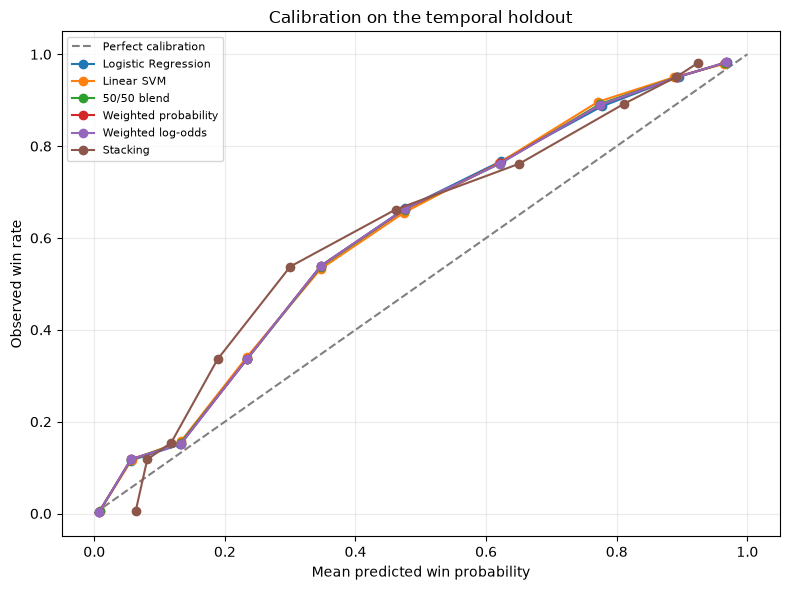

In [16]:
holdout_plot_methods = {
    "Logistic Regression": LR_COL,
    "Linear SVM": SVM_COL,
    "50/50 blend": "p_blend_50_50",
    "Weighted probability": "p_blend_weighted",
    "Weighted log-odds": "p_blend_log_odds",
    "Stacking": "p_stacking",
}

fig, ax = plt.subplots(figsize=(8, 6))
ax.plot([0, 1], [0, 1], "--", color="gray", label="Perfect calibration")
for name, col in holdout_plot_methods.items():
    observed, predicted = calibration_curve(
        holdout[TARGET_COL], holdout[col], n_bins=10, strategy="quantile"
    )
    ax.plot(predicted, observed, marker="o", label=name)
ax.set_xlabel("Mean predicted win probability")
ax.set_ylabel("Observed win rate")
ax.set_title("Calibration on the temporal holdout")
ax.grid(alpha=0.25)
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

## 10. Save the reports

These files record the weights tried, the comparison scores and how similar the two models' predictions are.

In [17]:
scores_path = REPORT_DIR / "ensemble_lr_svm_scores.csv"
diagnostics_path = REPORT_DIR / "ensemble_lr_svm_diagnostics.csv"
weight_search_path = REPORT_DIR / "ensemble_lr_svm_weight_search.csv"
selected_weights_path = REPORT_DIR / "ensemble_lr_svm_selected_weights.json"

scores.to_csv(scores_path, index=False)
diagnostics.to_csv(diagnostics_path, index=False)
weight_search.to_csv(weight_search_path, index=False)
with open(selected_weights_path, "w", encoding="utf-8") as f:
    json.dump({
        "selection_metric": "development OOF log loss",
        "probability_blend_lr_weight": BEST_PROB_WEIGHT,
        "probability_blend_svm_weight": 1 - BEST_PROB_WEIGHT,
        "log_odds_blend_lr_weight": BEST_LOG_ODDS_WEIGHT,
        "log_odds_blend_svm_weight": 1 - BEST_LOG_ODDS_WEIGHT,
    }, f, indent=2)

print("Saved:", scores_path)
print("Saved:", diagnostics_path)
print("Saved:", weight_search_path)
print("Saved:", selected_weights_path)

Saved: C:\Users\Lenovo\Documents\IPL ML\reports\ensemble_lr_svm_scores.csv
Saved: C:\Users\Lenovo\Documents\IPL ML\reports\ensemble_lr_svm_diagnostics.csv
Saved: C:\Users\Lenovo\Documents\IPL ML\reports\ensemble_lr_svm_weight_search.csv
Saved: C:\Users\Lenovo\Documents\IPL ML\reports\ensemble_lr_svm_selected_weights.json
